# Breast Cancer Histopathology Classification (BreakHis) — Kaggle notebook

Benign vs malignant classification on **BreakHis** with transfer learning, a **patient-wise** train/val/test split, augmentation comparison, soft-voting ensemble, and a full set of result plots.

**Setup on Kaggle**
1. **+ Add Input** → search `BreaKHis` (the `ambarish/breakhis` dataset) → Add.
2. Right sidebar → **Session options**: Accelerator = **GPU (T4 x2 or P100)**, **Internet = On** (needed once to download the ImageNet weights).
3. **Run All**. Set `QUICK_TEST = True` in the config cell first for a ~2 min smoke test.

Everything (plots, `results.csv`) is written to `/kaggle/working`.

## 1. Imports and config

In [1]:
import os, re, glob, time, math, random, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             precision_recall_curve, average_precision_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIG -----------------------------
CFG = dict(
    MODELS=["resnet50", "densenet121", "efficientnet_b0", "mobilenet_v2"],
    # any of: resnet50, resnext50, densenet121, efficientnet_b0, mobilenet_v2,
    #         vgg16, alexnet, convnext_tiny, shufflenet
    AUGS=["basic", "strong"],          # any of: basic, flip, rotation, strong
    EPOCHS=6,
    BATCH=32,
    LR=3e-4,
    IMG=224,
    WORKERS=4,
    FREEZE_BACKBONE=False,             # True = train only the new head (faster, usually worse)
    SAVE_WEIGHTS=False,                # True = save best weights of every run to /kaggle/working
    QUICK_TEST=False,                  # True = tiny subset, 1 model, 1 epoch (smoke test)
)
SEED = 42
ROOT = "/kaggle/input"
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device:", device, "| AMP:", use_amp)

Device: cuda | AMP: True


## 2. Find the images and build the dataframe

In [2]:
files = [f for f in glob.glob(f"{ROOT}/**/*.png", recursive=True)
         if f"{os.sep}benign{os.sep}" in f or f"{os.sep}malignant{os.sep}" in f]
assert files, "No BreakHis images found - did you attach the BreaKHis dataset via '+ Add Input'?"

NAME_RE = re.compile(r"SOB_([BM])_([A-Z]+)-(\d+-[0-9A-Za-z]+)-(\d+)-\d+", re.I)

def parse(f):
    parts = f.split(os.sep)
    m = NAME_RE.search(os.path.basename(f))
    slide_folder = os.path.basename(os.path.dirname(os.path.dirname(f)))
    return dict(
        path=f,
        label=int("malignant" in parts),                     # 0 = benign, 1 = malignant
        subtype=m.group(2).upper() if m else "NA",           # A, F, PT, TA | DC, LC, MC, PC
        patient=m.group(3) if m else slide_folder,           # patient / slide id
        magnification=(m.group(4) + "X") if m else os.path.basename(os.path.dirname(f)),
    )

df = pd.DataFrame([parse(f) for f in files])
print(f"{len(df)} images | {df.patient.nunique()} patients "
      f"| benign: {(df.label==0).sum()} | malignant: {(df.label==1).sum()}")
df.head()

7909 images | 81 patients | benign: 2480 | malignant: 5429


,path,label,subtype,patient,magnification
0,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,14-29960CD,200X
1,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,14-29960CD,200X
2,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,14-29960CD,200X
3,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,14-29960CD,200X
4,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,14-29960CD,200X


## 3. Quick EDA plots

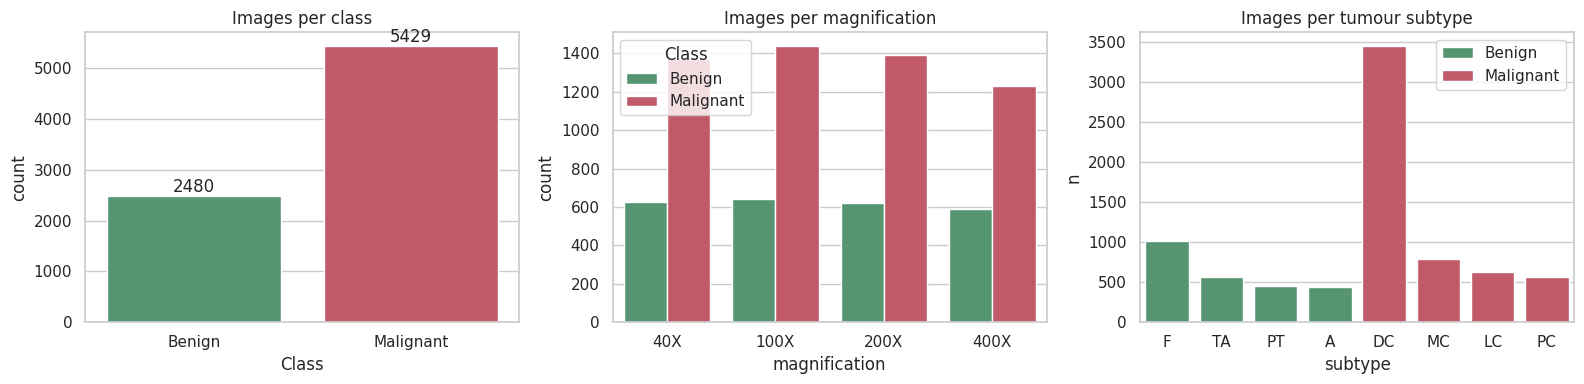

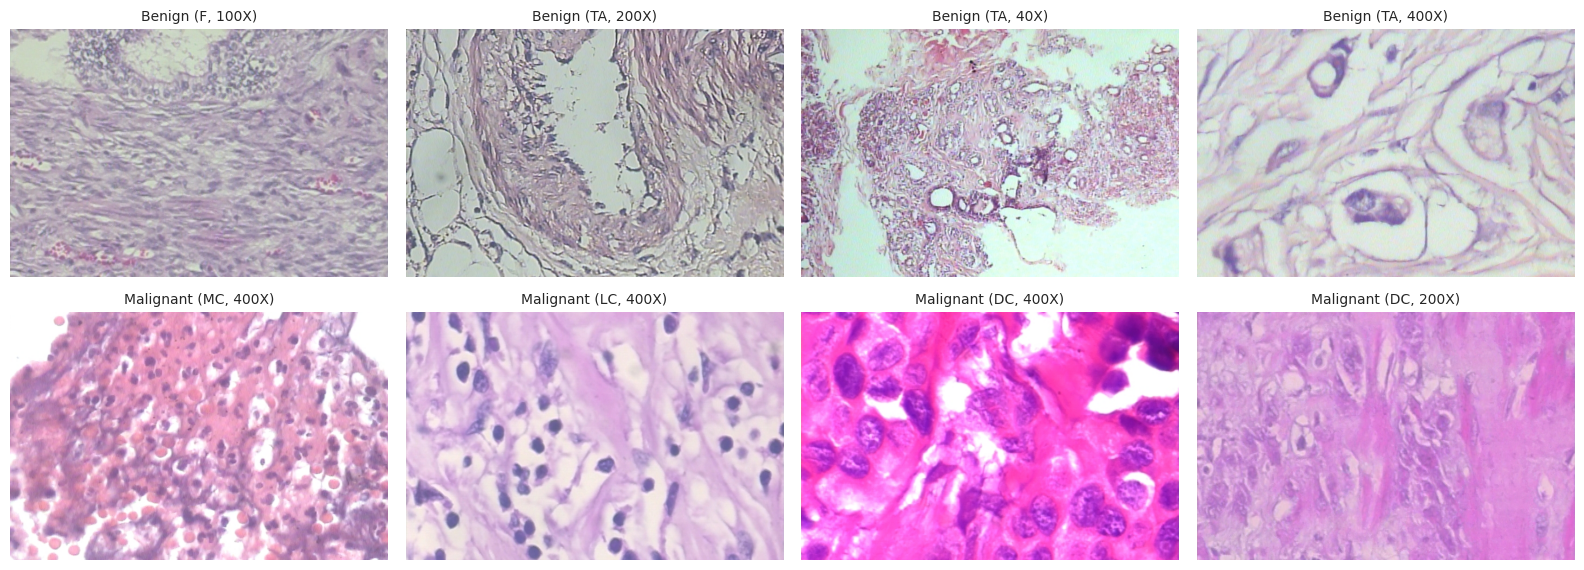

In [3]:
CLASS_NAMES = ["Benign", "Malignant"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=df.assign(Class=df.label.map(dict(enumerate(CLASS_NAMES)))),
              x="Class", palette=["#4C9F70", "#D1495B"], ax=axes[0])
axes[0].set_title("Images per class")
for c in axes[0].containers: axes[0].bar_label(c)

order = ["40X", "100X", "200X", "400X"]
sns.countplot(data=df.assign(Class=df.label.map(dict(enumerate(CLASS_NAMES)))),
              x="magnification", hue="Class", order=[o for o in order if o in df.magnification.unique()],
              palette=["#4C9F70", "#D1495B"], ax=axes[1])
axes[1].set_title("Images per magnification")

sub = df.groupby(["subtype", "label"]).size().reset_index(name="n").sort_values(["label", "n"], ascending=[True, False])
sns.barplot(data=sub, x="subtype", y="n", hue=sub.label.map(dict(enumerate(CLASS_NAMES))),
            palette=["#4C9F70", "#D1495B"], dodge=False, ax=axes[2])
axes[2].set_title("Images per tumour subtype"); axes[2].set_xlabel("subtype"); axes[2].legend(title="")
fig.tight_layout(); fig.savefig(f"{OUT}/eda_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

# sample images
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for r, lab in enumerate([0, 1]):
    for c, (_, row) in enumerate(df[df.label == lab].sample(4, random_state=1).iterrows()):
        axes[r, c].imshow(Image.open(row.path).convert("RGB")); axes[r, c].axis("off")
        axes[r, c].set_title(f"{CLASS_NAMES[lab]} ({row.subtype}, {row.magnification})", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT}/eda_samples.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Patient-wise split

BreakHis has ~82 patients and many images per patient. A random *image-level* split puts images of the same patient in both train and test, which inflates scores. Here every patient lands in exactly one of train / val / test (stratified by class as far as possible).

In [4]:
def group_split(d, n_splits, seed=SEED):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    tr, te = next(sgkf.split(d, d["label"], groups=d["patient"]))
    return d.iloc[tr].reset_index(drop=True), d.iloc[te].reset_index(drop=True)

trainval_df, test_df = group_split(df, 6)          # ~1/6 of patients -> test
train_df, val_df = group_split(trainval_df, 6)     # ~1/6 of the rest -> val

if CFG["QUICK_TEST"]:
    train_df = train_df.sample(256, random_state=SEED).reset_index(drop=True)
    val_df   = val_df.sample(128, random_state=SEED).reset_index(drop=True)
    test_df  = test_df.sample(128, random_state=SEED).reset_index(drop=True)
    CFG.update(MODELS=CFG["MODELS"][-1:], AUGS=CFG["AUGS"][:1], EPOCHS=1, WORKERS=2)

# sanity: no patient in two splits
sets = {k: set(v.patient) for k, v in dict(train=train_df, val=val_df, test=test_df).items()}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])

summary = pd.DataFrame({k: dict(images=len(v), patients=v.patient.nunique(),
                                malignant_pct=round(100 * v.label.mean(), 1))
                        for k, v in dict(train=train_df, val=val_df, test=test_df).items()}).T
print(summary)

# class weights from the training split (BreakHis is ~2.2:1 malignant:benign)
cnt = np.bincount(train_df.label, minlength=2)
class_weights = torch.tensor(len(train_df) / (2.0 * np.maximum(cnt, 1)), dtype=torch.float32).to(device)
print("class weights:", class_weights.cpu().numpy().round(3))

       images  patients  malignant_pct
train  5224.0      57.0           65.2
val    1325.0      11.0           73.7
test   1360.0      13.0           77.1
class weights: [1.435 0.767]


## 5. Dataset, augmentations, models

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats (needed for pretrained nets)

def build_tfms(aug):
    size = (CFG["IMG"], CFG["IMG"])
    R = transforms.Resize(size)
    train_ops = {
        "basic":    [R],
        "flip":     [R, transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip()],
        "rotation": [R, transforms.RandomRotation(20)],
        "strong":   [R, transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
                     transforms.RandomRotation(30),
                     transforms.ColorJitter(0.2, 0.2, 0.2, 0.02)],
    }[aug]
    tail = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    # augmentation is applied to TRAIN only; val/test just resize + normalise
    return transforms.Compose(train_ops + tail), transforms.Compose([R] + tail)

class ImgDS(Dataset):
    def __init__(self, d, tf): self.paths, self.labels, self.tf = d.path.tolist(), d.label.tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

def make_loaders(aug):
    train_tf, eval_tf = build_tfms(aug)
    kw = dict(batch_size=CFG["BATCH"], num_workers=CFG["WORKERS"], pin_memory=use_amp,
              persistent_workers=CFG["WORKERS"] > 0)
    return (DataLoader(ImgDS(train_df, train_tf), shuffle=True, drop_last=True, **kw),
            DataLoader(ImgDS(val_df, eval_tf), shuffle=False, **kw),
            DataLoader(ImgDS(test_df, eval_tf), shuffle=False, **kw))

def build_model(name, freeze_backbone=False):
    W = "DEFAULT"
    if name == "resnet50":          m = models.resnet50(weights=W)
    elif name == "resnext50":       m = models.resnext50_32x4d(weights=W)
    elif name == "densenet121":     m = models.densenet121(weights=W)
    elif name == "efficientnet_b0": m = models.efficientnet_b0(weights=W)
    elif name == "mobilenet_v2":    m = models.mobilenet_v2(weights=W)
    elif name == "vgg16":           m = models.vgg16(weights=W)
    elif name == "alexnet":         m = models.alexnet(weights=W)
    elif name == "convnext_tiny":   m = models.convnext_tiny(weights=W)
    elif name == "shufflenet":      m = models.shufflenet_v2_x1_0(weights=W)
    else: raise ValueError(name)

    if freeze_backbone:
        for p in m.parameters(): p.requires_grad = False

    # replace the classification head (new layers are trainable by default)
    if name in ("resnet50", "resnext50", "shufflenet"): m.fc = nn.Linear(m.fc.in_features, 2)
    elif name == "densenet121":                          m.classifier = nn.Linear(m.classifier.in_features, 2)
    elif name in ("vgg16", "alexnet"):                   m.classifier[6] = nn.Linear(m.classifier[6].in_features, 2)
    elif name in ("efficientnet_b0", "mobilenet_v2"):    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
    elif name == "convnext_tiny":                        m.classifier[2] = nn.Linear(m.classifier[2].in_features, 2)
    return m.to(device)

## 6. Training / evaluation helpers

In [6]:
def compute_metrics(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(
        Accuracy=accuracy_score(y, pred),
        Precision=precision_score(y, pred, zero_division=0),
        Recall=recall_score(y, pred, zero_division=0),            # sensitivity for malignant
        Specificity=tn / (tn + fp) if (tn + fp) else 0.0,
        F1=f1_score(y, pred, zero_division=0),
        AUC=roc_auc_score(y, p) if len(set(y)) > 1 else float("nan"),
        TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn),
    )

def patient_level_acc(d, p):
    t = d.assign(prob=np.asarray(p)).groupby("patient").agg(prob=("prob", "mean"), label=("label", "first"))
    return accuracy_score(t.label, (t.prob >= 0.5).astype(int))

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total, n, probs, ys = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
        total += loss.item() * x.size(0); n += x.size(0)
        probs.append(F.softmax(out.float(), 1)[:, 1].detach().cpu()); ys.append(y.cpu())
    probs, ys = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    return total / n, probs, ys

def fit(name, aug):
    seed_everything()
    train_dl, val_dl, test_dl = make_loaders(aug)
    model = build_model(name, CFG["FREEZE_BACKBONE"])
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=CFG["LR"], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["EPOCHS"])
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    hist, best_f1, best_state, t0 = [], -1, None, time.time()
    for ep in range(1, CFG["EPOCHS"] + 1):
        tr_loss, tr_p, tr_y = run_epoch(model, train_dl, criterion, optimizer, scaler)
        va_loss, va_p, va_y = run_epoch(model, val_dl, criterion)
        scheduler.step()
        tr_m, va_m = compute_metrics(tr_y, tr_p), compute_metrics(va_y, va_p)
        hist.append(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss,
                         train_acc=tr_m["Accuracy"], val_acc=va_m["Accuracy"], val_f1=va_m["F1"]))
        if va_m["F1"] > best_f1:
            best_f1 = va_m["F1"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"  ep {ep}/{CFG['EPOCHS']}  train_loss {tr_loss:.4f}  val_loss {va_loss:.4f}  "
              f"val_acc {va_m['Accuracy']:.4f}  val_f1 {va_m['F1']:.4f}")

    model.load_state_dict(best_state)                      # evaluate the best-on-validation checkpoint
    te_loss, te_p, te_y = run_epoch(model, test_dl, criterion)
    if CFG["SAVE_WEIGHTS"]:
        torch.save(best_state, f"{OUT}/{name}_{aug}.pt")
    del model, optimizer, best_state; torch.cuda.empty_cache()
    return dict(model=name, aug=aug, history=pd.DataFrame(hist), best_val_f1=best_f1,
                probs=te_p, y=te_y, metrics=compute_metrics(te_y, te_p),
                patient_acc=patient_level_acc(test_df, te_p), minutes=(time.time() - t0) / 60)

## 7. Run the experiments (models × augmentations)

In [7]:
RUNS = {}
for name in CFG["MODELS"]:
    for aug in CFG["AUGS"]:
        print(f"\n=== {name} + {aug} ===")
        RUNS[(name, aug)] = fit(name, aug)
        m = RUNS[(name, aug)]["metrics"]
        print(f"  TEST -> acc {m['Accuracy']:.4f} | F1 {m['F1']:.4f} | AUC {m['AUC']:.4f} "
              f"| {RUNS[(name, aug)]['minutes']:.1f} min")


=== resnet50 + basic ===
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 213MB/s]


  ep 1/6  train_loss 0.2126  val_loss 0.7022  val_acc 0.7925  val_f1 0.8527
  ep 2/6  train_loss 0.1132  val_loss 1.5949  val_acc 0.7230  val_f1 0.7949
  ep 3/6  train_loss 0.0476  val_loss 0.7219  val_acc 0.8113  val_f1 0.8666
  ep 4/6  train_loss 0.0213  val_loss 0.8355  val_acc 0.7728  val_f1 0.8347
  ep 5/6  train_loss 0.0113  val_loss 0.8009  val_acc 0.7962  val_f1 0.8541
  ep 6/6  train_loss 0.0050  val_loss 0.8919  val_acc 0.8008  val_f1 0.8593
  TEST -> acc 0.9235 | F1 0.9509 | AUC 0.9582 | 4.6 min

=== resnet50 + strong ===
  ep 1/6  train_loss 0.2973  val_loss 0.5040  val_acc 0.8317  val_f1 0.8829
  ep 2/6  train_loss 0.1708  val_loss 0.8616  val_acc 0.7042  val_f1 0.7910
  ep 3/6  train_loss 0.1082  val_loss 1.1585  val_acc 0.6868  val_f1 0.7624
  ep 4/6  train_loss 0.0786  val_loss 0.8581  val_acc 0.7653  val_f1 0.8320
  ep 5/6  train_loss 0.0531  val_loss 0.8048  val_acc 0.7819  val_f1 0.8457
  ep 6/6  train_loss 0.0351  val_loss 0.7355  val_acc 0.8091  val_f1 0.8658
  TES

100%|██████████| 30.8M/30.8M [00:00<00:00, 245MB/s]


  ep 1/6  train_loss 0.2162  val_loss 0.8861  val_acc 0.7064  val_f1 0.7705
  ep 2/6  train_loss 0.0936  val_loss 1.0853  val_acc 0.6777  val_f1 0.7481
  ep 3/6  train_loss 0.0505  val_loss 1.1845  val_acc 0.7540  val_f1 0.8224
  ep 4/6  train_loss 0.0125  val_loss 0.7298  val_acc 0.8038  val_f1 0.8629
  ep 5/6  train_loss 0.0115  val_loss 0.7964  val_acc 0.7977  val_f1 0.8588
  ep 6/6  train_loss 0.0025  val_loss 0.9491  val_acc 0.7796  val_f1 0.8445
  TEST -> acc 0.9610 | F1 0.9751 | AUC 0.9911 | 4.5 min

=== densenet121 + strong ===
  ep 1/6  train_loss 0.2856  val_loss 0.9749  val_acc 0.7185  val_f1 0.7812
  ep 2/6  train_loss 0.1641  val_loss 1.1085  val_acc 0.6574  val_f1 0.7248
  ep 3/6  train_loss 0.1206  val_loss 0.8227  val_acc 0.7487  val_f1 0.8201
  ep 4/6  train_loss 0.0948  val_loss 0.6394  val_acc 0.8008  val_f1 0.8585
  ep 5/6  train_loss 0.0684  val_loss 0.5591  val_acc 0.8106  val_f1 0.8675
  ep 6/6  train_loss 0.0413  val_loss 0.6307  val_acc 0.8008  val_f1 0.8596
  

100%|██████████| 20.5M/20.5M [00:00<00:00, 243MB/s]


  ep 1/6  train_loss 0.1902  val_loss 0.8454  val_acc 0.7389  val_f1 0.8146
  ep 2/6  train_loss 0.0678  val_loss 0.8504  val_acc 0.7691  val_f1 0.8365
  ep 3/6  train_loss 0.0434  val_loss 0.9080  val_acc 0.7615  val_f1 0.8297
  ep 4/6  train_loss 0.0235  val_loss 0.8711  val_acc 0.7849  val_f1 0.8486
  ep 5/6  train_loss 0.0165  val_loss 1.1198  val_acc 0.7525  val_f1 0.8219
  ep 6/6  train_loss 0.0102  val_loss 1.0625  val_acc 0.7532  val_f1 0.8230
  TEST -> acc 0.9074 | F1 0.9429 | AUC 0.9758 | 4.5 min

=== efficientnet_b0 + strong ===
  ep 1/6  train_loss 0.2584  val_loss 0.6233  val_acc 0.7457  val_f1 0.8082
  ep 2/6  train_loss 0.1335  val_loss 0.4353  val_acc 0.8309  val_f1 0.8819
  ep 3/6  train_loss 0.0949  val_loss 0.6613  val_acc 0.7917  val_f1 0.8467
  ep 4/6  train_loss 0.0763  val_loss 0.4944  val_acc 0.8725  val_f1 0.9131
  ep 5/6  train_loss 0.0522  val_loss 0.4648  val_acc 0.8626  val_f1 0.9028
  ep 6/6  train_loss 0.0425  val_loss 0.5730  val_acc 0.8430  val_f1 0.889

100%|██████████| 13.6M/13.6M [00:00<00:00, 224MB/s]


  ep 1/6  train_loss 0.2184  val_loss 0.5794  val_acc 0.8272  val_f1 0.8831
  ep 2/6  train_loss 0.0759  val_loss 0.6201  val_acc 0.7947  val_f1 0.8576
  ep 3/6  train_loss 0.0441  val_loss 0.5672  val_acc 0.8355  val_f1 0.8880
  ep 4/6  train_loss 0.0278  val_loss 0.7367  val_acc 0.7857  val_f1 0.8420
  ep 5/6  train_loss 0.0127  val_loss 0.6891  val_acc 0.8166  val_f1 0.8708
  ep 6/6  train_loss 0.0057  val_loss 0.6081  val_acc 0.8309  val_f1 0.8839
  TEST -> acc 0.9007 | F1 0.9392 | AUC 0.9609 | 4.4 min

=== mobilenet_v2 + strong ===
  ep 1/6  train_loss 0.2989  val_loss 0.5310  val_acc 0.8325  val_f1 0.8878
  ep 2/6  train_loss 0.1539  val_loss 0.6544  val_acc 0.8158  val_f1 0.8741
  ep 3/6  train_loss 0.1251  val_loss 0.5555  val_acc 0.8196  val_f1 0.8727
  ep 4/6  train_loss 0.0966  val_loss 0.8102  val_acc 0.7675  val_f1 0.8321
  ep 5/6  train_loss 0.0746  val_loss 0.6791  val_acc 0.7955  val_f1 0.8548
  ep 6/6  train_loss 0.0530  val_loss 0.7478  val_acc 0.7834  val_f1 0.8463
 

## 8. Soft-voting ensemble

For each architecture the augmentation is chosen by **validation** F1 (not test), then the test probabilities of those models are averaged.

In [8]:
best_key = {}
for (m, a), r in RUNS.items():
    if m not in best_key or r["best_val_f1"] > RUNS[best_key[m]]["best_val_f1"]:
        best_key[m] = (m, a)

if len(best_key) > 1:
    keys = list(best_key.values())
    ens_p = np.mean([RUNS[k]["probs"] for k in keys], axis=0)
    y_test = RUNS[keys[0]]["y"]
    RUNS[("ensemble", "soft-vote")] = dict(
        model="ensemble", aug="soft-vote", history=None, best_val_f1=float("nan"),
        probs=ens_p, y=y_test, metrics=compute_metrics(y_test, ens_p),
        patient_acc=patient_level_acc(test_df, ens_p), minutes=float("nan"))
    print("Ensemble of:", keys)
else:
    print("Need >= 2 models for an ensemble - skipped.")

Ensemble of: [('resnet50', 'strong'), ('densenet121', 'strong'), ('efficientnet_b0', 'strong'), ('mobilenet_v2', 'basic')]


## 9. Results table

In [9]:
rows = []
for (m, a), r in RUNS.items():
    rows.append({"Model": m, "Augmentation": a,
                 **{k: (round(v, 4) if isinstance(v, float) else v) for k, v in r["metrics"].items()},
                 "PatientAcc": round(r["patient_acc"], 4), "Minutes": round(r["minutes"], 1)})
results_df = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
results_df.to_csv(f"{OUT}/results.csv", index=False)
display(results_df)

# which config is best on VALIDATION (what you'd report as your chosen model)
cand = {k: v for k, v in RUNS.items() if v["history"] is not None}
bk = max(cand, key=lambda k: cand[k]["best_val_f1"])
print(f"\nBest single config by validation F1: {bk}  ->  test F1 {RUNS[bk]['metrics']['F1']:.4f}")

,Model,Augmentation,Accuracy,Precision,Recall,Specificity,F1,AUC,TP,TN,FP,FN,PatientAcc,Minutes
0,densenet121,basic,0.9610,0.9603,0.9905,0.8617,0.9751,0.9911,1039,268,43,10,1.0000,4.5
1,densenet121,strong,0.9346,0.9293,0.9905,0.7460,0.9589,0.9789,1039,232,79,10,0.9231,5.4
2,ensemble,soft-vote,0.9279,0.9182,0.9952,0.7010,0.9552,0.9884,1044,218,93,5,0.9231,NaN
3,efficientnet_b0,strong,0.9221,0.9132,0.9933,0.6817,0.9516,0.9742,1042,212,99,7,0.9231,5.1
4,resnet50,basic,0.9235,0.9420,0.9600,0.8006,0.9509,0.9582,1007,249,62,42,1.0000,4.6
5,resnet50,strong,0.9235,0.9655,0.9342,0.8875,0.9496,0.9711,980,276,35,69,1.0000,5.2
6,efficientnet_b0,basic,0.9074,0.8989,0.9914,0.6238,0.9429,0.9758,1040,194,117,9,0.9231,4.5
7,mobilenet_v2,basic,0.9007,0.8899,0.9943,0.5852,0.9392,0.9609,1043,182,129,6,0.9231,4.4
8,mobilenet_v2,strong,0.8993,0.8858,0.9981,0.5659,0.9386,0.9772,1047,176,135,2,0.9231,5.0



Best single config by validation F1: ('efficientnet_b0', 'strong')  ->  test F1 0.9516


## 10. Plots

### 10.1 Training curves (loss and validation accuracy per model)

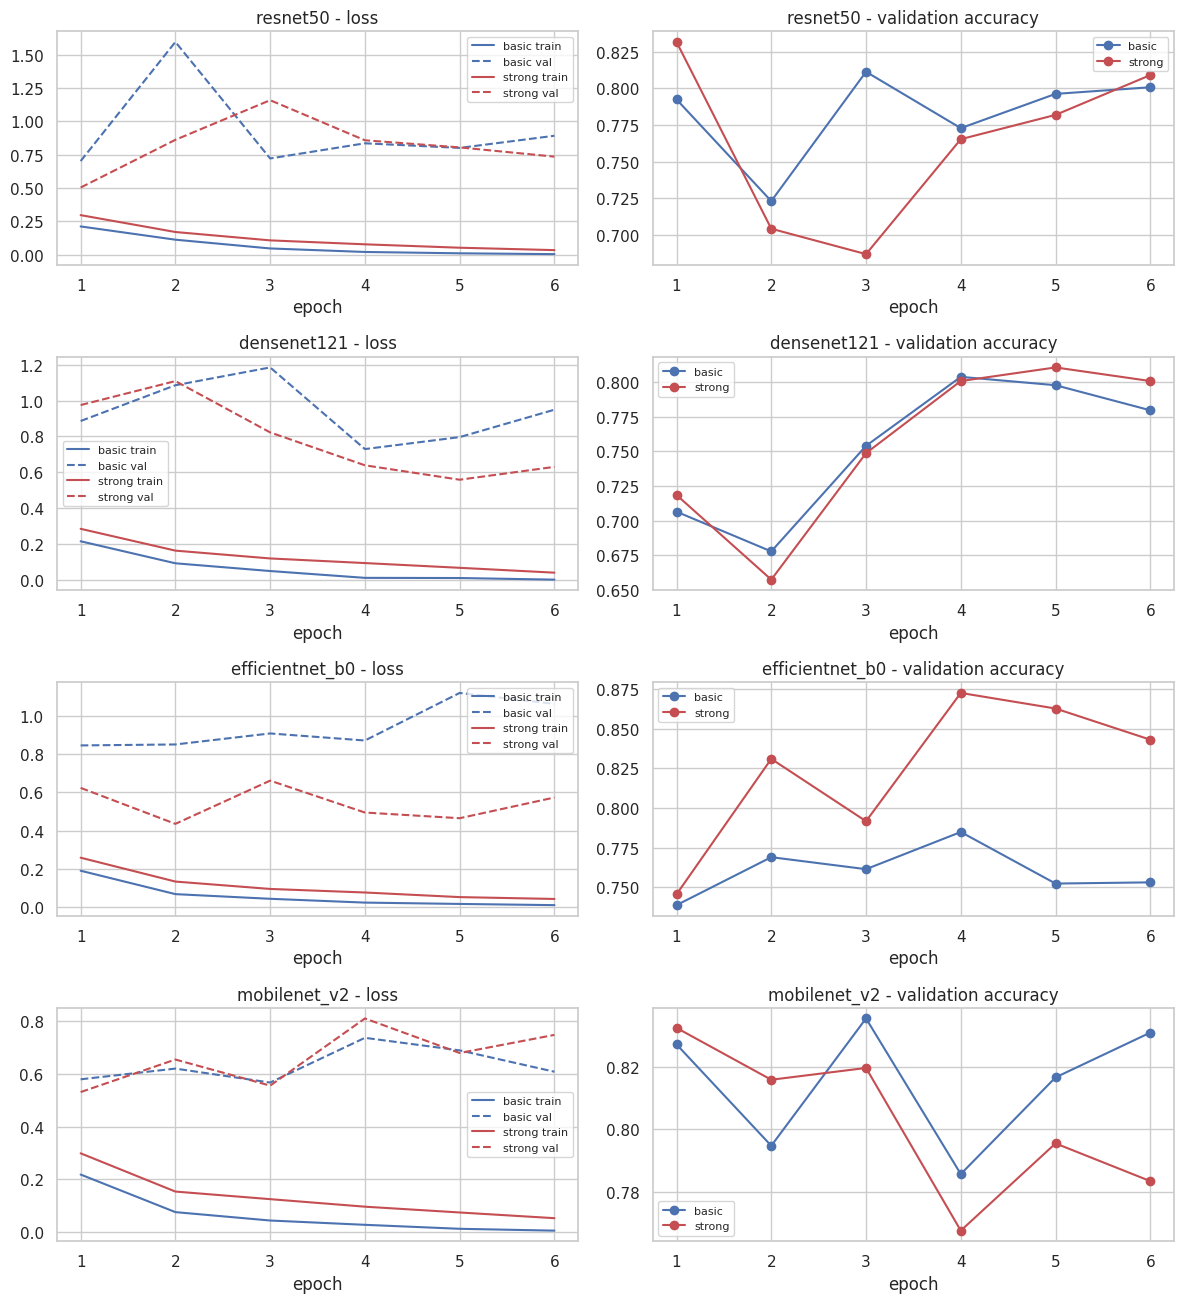

In [10]:
PAL = dict(zip(["basic", "flip", "rotation", "strong"], sns.color_palette("deep", 4)))
models_run = [m for m in CFG["MODELS"] if any(k[0] == m for k in RUNS)]
fig, axes = plt.subplots(len(models_run), 2, figsize=(12, 3.3 * len(models_run)), squeeze=False)
for i, m in enumerate(models_run):
    for (mm, aug), r in RUNS.items():
        if mm != m or r["history"] is None: continue
        h = r["history"]
        axes[i, 0].plot(h.epoch, h.train_loss, color=PAL[aug], ls="-",  label=f"{aug} train")
        axes[i, 0].plot(h.epoch, h.val_loss,   color=PAL[aug], ls="--", label=f"{aug} val")
        axes[i, 1].plot(h.epoch, h.val_acc, color=PAL[aug], marker="o", label=f"{aug}")
    axes[i, 0].set_title(f"{m} - loss"); axes[i, 0].set_xlabel("epoch"); axes[i, 0].legend(fontsize=8)
    axes[i, 1].set_title(f"{m} - validation accuracy"); axes[i, 1].set_xlabel("epoch"); axes[i, 1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

### 10.2 Metric comparison (grouped bars) and augmentation heatmap

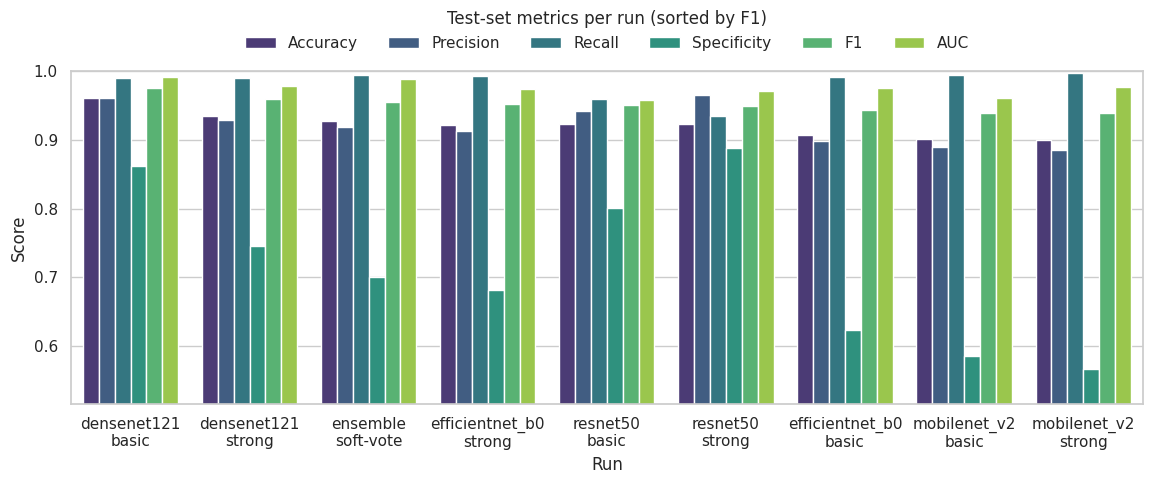

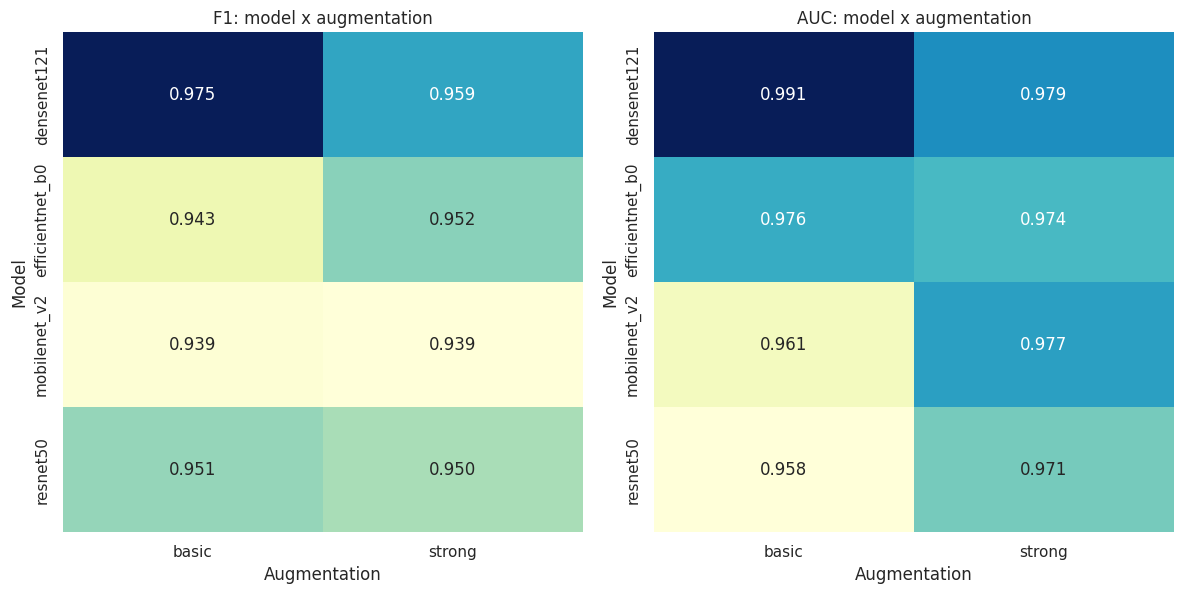

In [11]:
metric_cols = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC"]
plot_df = results_df.assign(Run=results_df.Model + "\n" + results_df.Augmentation)
plot_df = plot_df.sort_values("F1", ascending=False)
long = plot_df.melt(id_vars="Run", value_vars=metric_cols, var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(max(10, 1.3 * len(plot_df)), 5))
sns.barplot(data=long, x="Run", y="Score", hue="Metric", ax=ax, palette="viridis")
ax.set_ylim(max(0, long.Score.min() - 0.05), 1.0)
ax.set_title("Test-set metrics per run (sorted by F1)", pad=34)
ax.legend(ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)
fig.tight_layout(); fig.savefig(f"{OUT}/metrics_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

# model x augmentation heatmap (F1 and AUC)
grid = results_df[results_df.Model != "ensemble"]
fig, axes = plt.subplots(1, 2, figsize=(12, 0.9 * grid.Model.nunique() + 2.5))
for ax, met in zip(axes, ["F1", "AUC"]):
    pv = grid.pivot(index="Model", columns="Augmentation", values=met)
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, cbar=False)
    ax.set_title(f"{met}: model x augmentation")
fig.tight_layout(); fig.savefig(f"{OUT}/heatmap_model_aug.png", dpi=150, bbox_inches="tight"); plt.show()

### 10.3 Confusion matrices

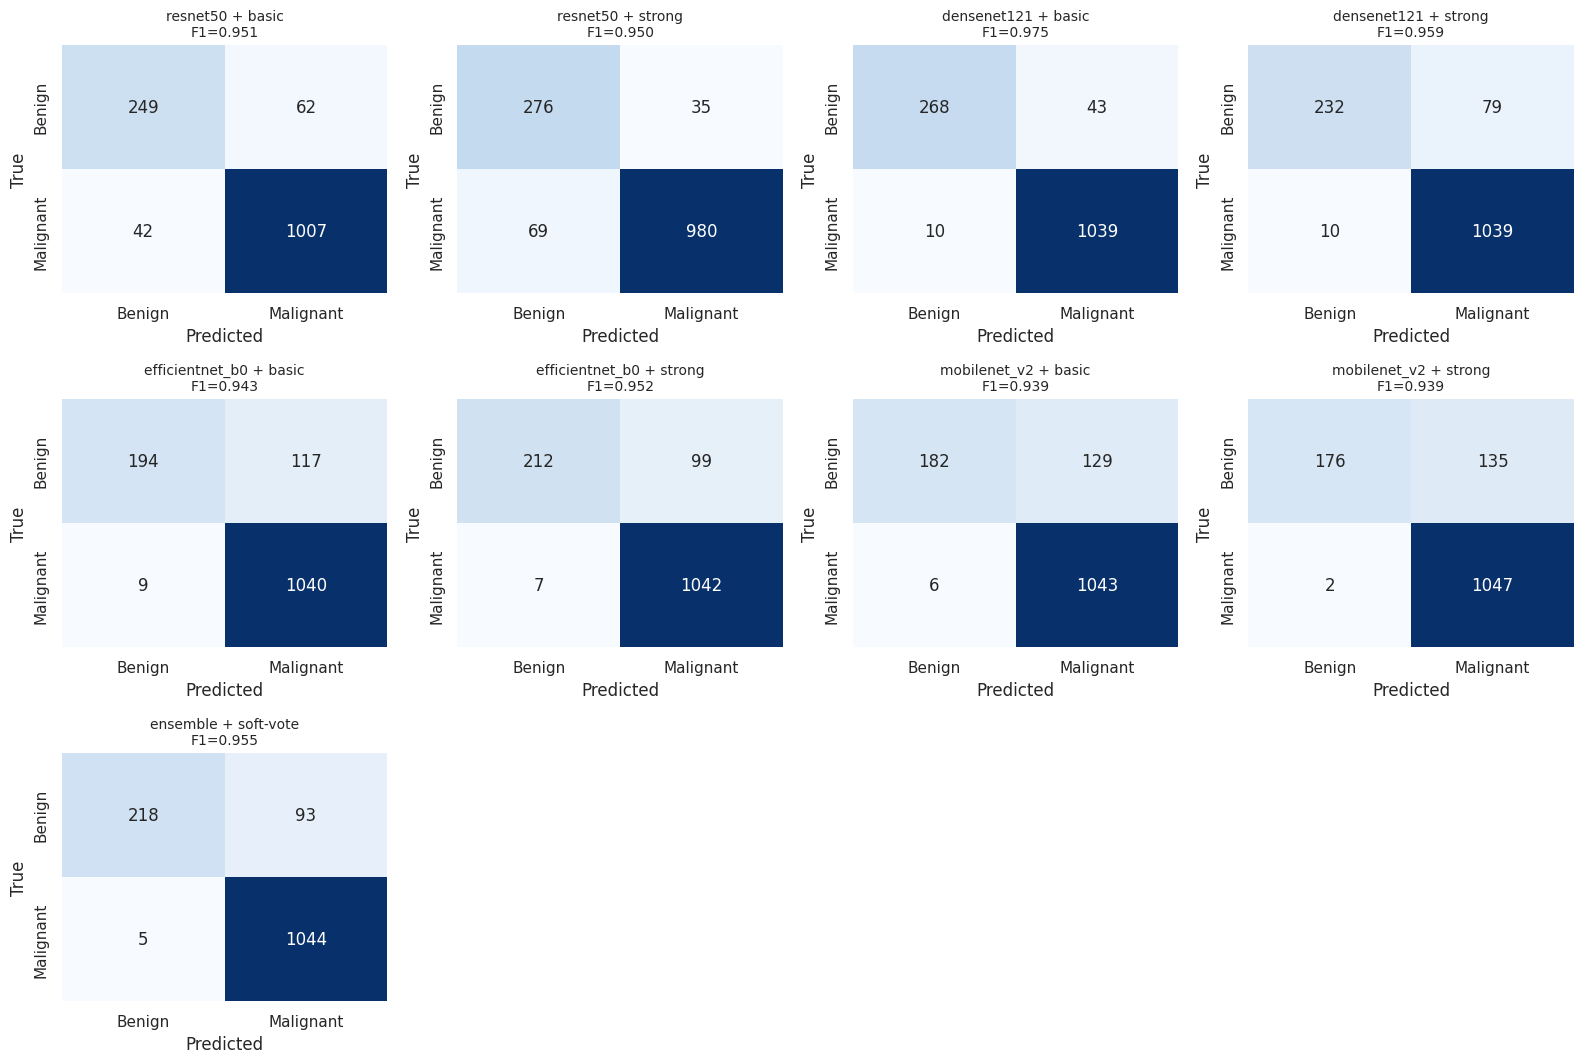

In [12]:
keys = list(RUNS.keys())
ncol = min(4, len(keys)); nrow = math.ceil(len(keys) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.6 * nrow), squeeze=False)
for ax, k in zip(axes.ravel(), keys):
    m = RUNS[k]["metrics"]
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{k[0]} + {k[1]}\nF1={m['F1']:.3f}", fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for ax in axes.ravel()[len(keys):]: ax.axis("off")
fig.tight_layout(); fig.savefig(f"{OUT}/confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

### 10.4 ROC and Precision-Recall curves

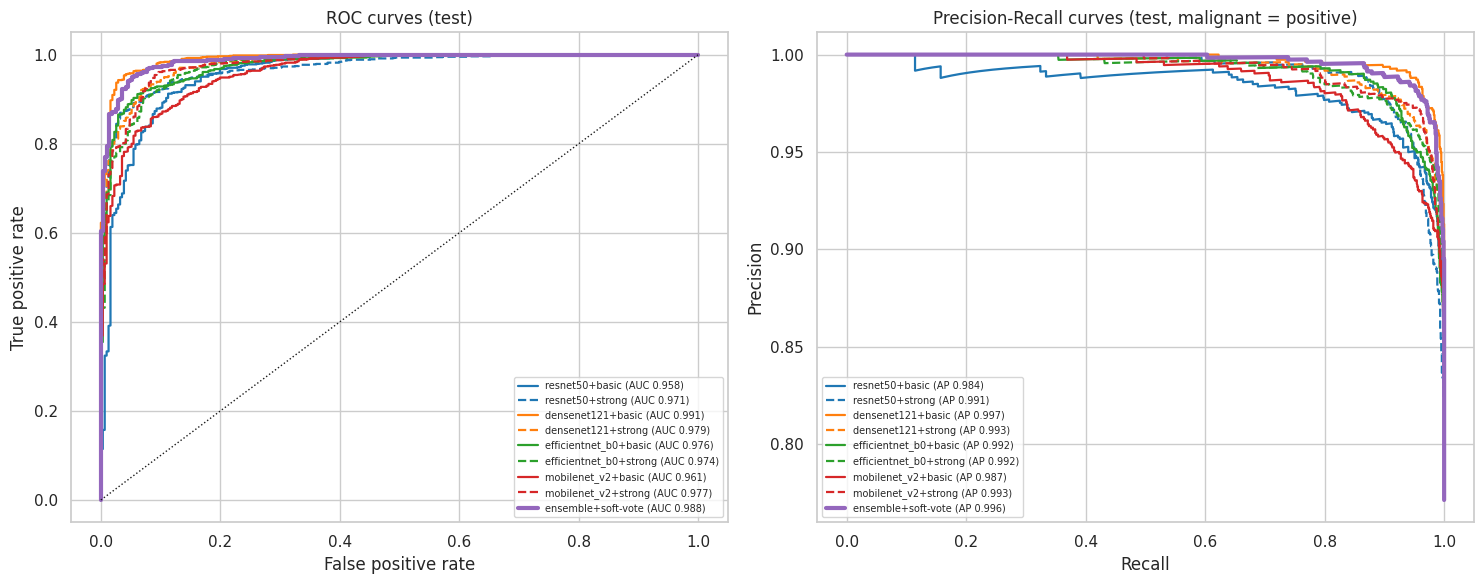

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cmap = sns.color_palette("tab10", len(models_run) + 1)
col = {m: cmap[i] for i, m in enumerate(models_run + ["ensemble"])}
ls = {"basic": "-", "flip": ":", "rotation": "-.", "strong": "--", "soft-vote": "-"}

for (m, a), r in RUNS.items():
    y, p = r["y"], r["probs"]
    fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
    lw = 3 if m == "ensemble" else 1.6
    axes[0].plot(fpr, tpr, color=col[m], ls=ls[a], lw=lw, label=f"{m}+{a} (AUC {roc_auc_score(y, p):.3f})")
    axes[1].plot(rc, pr, color=col[m], ls=ls[a], lw=lw, label=f"{m}+{a} (AP {average_precision_score(y, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set(title="ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-Recall curves (test, malignant = positive)", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(fontsize=7, loc="lower right" if ax is axes[0] else "lower left")
fig.tight_layout(); fig.savefig(f"{OUT}/roc_pr_curves.png", dpi=150, bbox_inches="tight"); plt.show()

### 10.5 Image-level vs patient-level accuracy, and training cost

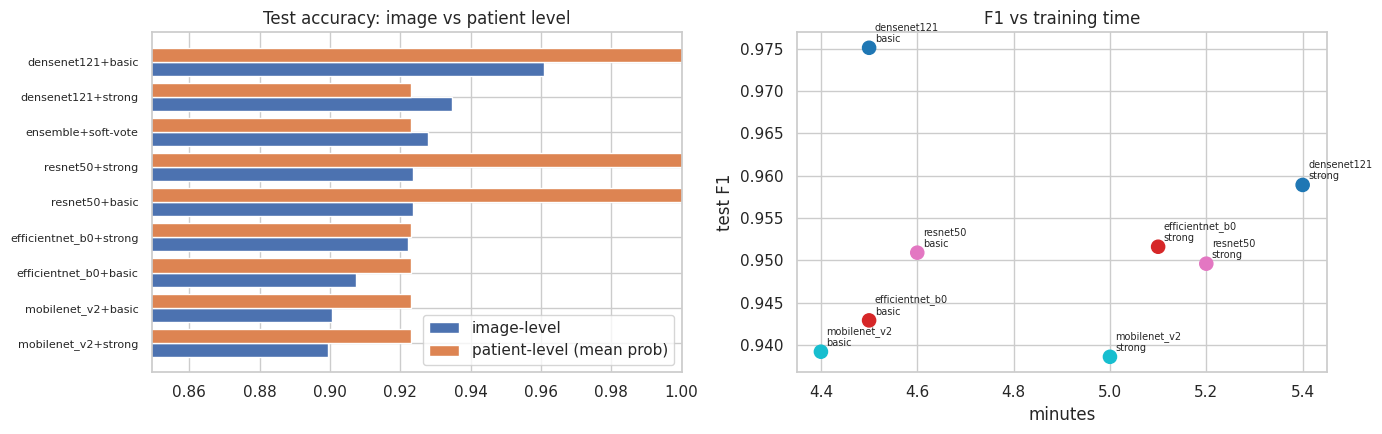

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
d = results_df.assign(Run=results_df.Model + "+" + results_df.Augmentation).sort_values("Accuracy")
y_pos = np.arange(len(d))
axes[0].barh(y_pos - 0.2, d.Accuracy, height=0.4, label="image-level")
axes[0].barh(y_pos + 0.2, d.PatientAcc, height=0.4, label="patient-level (mean prob)")
axes[0].set_yticks(y_pos); axes[0].set_yticklabels(d.Run, fontsize=8)
axes[0].set_xlim(max(0, min(d.Accuracy.min(), d.PatientAcc.min()) - 0.05), 1.0)
axes[0].set_title("Test accuracy: image vs patient level"); axes[0].legend()

t = results_df.dropna(subset=["Minutes"])
sc = axes[1].scatter(t.Minutes, t.F1, s=90, c=pd.factorize(t.Model)[0], cmap="tab10")
for _, r in t.iterrows(): axes[1].annotate(f"{r.Model}\n{r.Augmentation}", (r.Minutes, r.F1), fontsize=7, xytext=(4, 4), textcoords="offset points")
axes[1].set(title="F1 vs training time", xlabel="minutes", ylabel="test F1")
fig.tight_layout(); fig.savefig(f"{OUT}/accuracy_patient_and_time.png", dpi=150, bbox_inches="tight"); plt.show()

### 10.6 Most confident mistakes of the best config

('efficientnet_b0', 'strong'): 106 mistakes out of 1360 test images


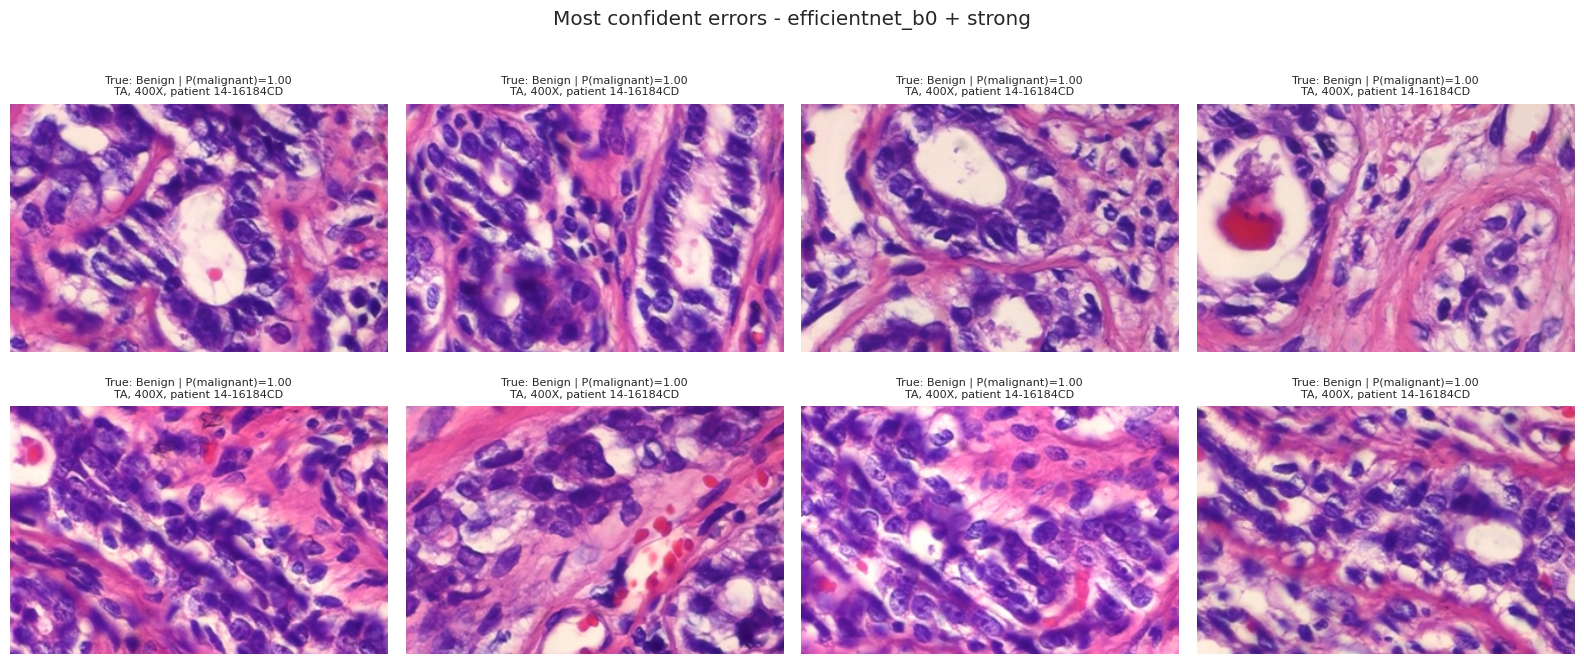

In [15]:
r = RUNS[bk]
y, p = r["y"], r["probs"]
wrong = np.where((p >= 0.5).astype(int) != y)[0]
wrong = wrong[np.argsort(-np.abs(p[wrong] - 0.5))][:8]          # most confidently wrong first
print(f"{bk}: {int(((p >= 0.5).astype(int) != y).sum())} mistakes out of {len(y)} test images")

if len(wrong):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        row = test_df.iloc[i]
        ax.imshow(Image.open(row.path).convert("RGB"))
        ax.set_title(f"True: {CLASS_NAMES[y[i]]} | P(malignant)={p[i]:.2f}\n{row.subtype}, {row.magnification}, patient {row.patient}", fontsize=8)
    fig.suptitle(f"Most confident errors - {bk[0]} + {bk[1]}", y=1.0)
    fig.tight_layout(); fig.savefig(f"{OUT}/misclassified.png", dpi=150, bbox_inches="tight"); plt.show()

## Notes for the write-up
* Report **mean ± std over several patient-wise splits** if you can: with only ~82 patients, one 6-fold split has ~14 test patients and the numbers are noisy. Wrap sections 4–9 in a loop over seeds, or use `StratifiedGroupKFold(n_splits=5)` and iterate over all folds.
* Compare **recall (sensitivity)** and **specificity** — missing a malignant case is the costly error.
* All outputs: `results.csv` and the `*.png` figures in `/kaggle/working` (download from the Output tab).